In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_style("whitegrid")

from sklearn.linear_model import LinearRegression

In [2]:
df = pd.read_csv(r"D:\Documents\NTI_ML\Tasks\house_prices_large_dataset.csv")
df.head()

,House_ID,Location,Area_sqft,Bedrooms,Bathrooms,Garage,Year_Built,Price_USD,Property_Type,Floor,Distance_to_CityCenter_km
0,1,Seattle,8077,3,4,3,2000,2973292,Bungalow,NaN,9.56
1,2,Houston,4211,1,2,0,1953,861522,Bungalow,NaN,21.84
2,3,Miami,3460,7,1,0,2007,1096391,Apartment,22.0,21.64
3,4,Seattle,5330,4,5,2,1973,1755822,Bungalow,NaN,45.83
4,5,Chicago,5958,2,3,3,1958,1491114,Townhouse,NaN,32.08


In [3]:
df.shape

(50000, 11)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   House_ID                   50000 non-null  int64  
 1   Location                   50000 non-null  str    
 2   Area_sqft                  50000 non-null  int64  
 3   Bedrooms                   50000 non-null  int64  
 4   Bathrooms                  50000 non-null  int64  
 5   Garage                     50000 non-null  int64  
 6   Year_Built                 50000 non-null  int64  
 7   Price_USD                  50000 non-null  int64  
 8   Property_Type              50000 non-null  str    
 9   Floor                      12533 non-null  float64
 10  Distance_to_CityCenter_km  50000 non-null  float64
dtypes: float64(2), int64(7), str(2)
memory usage: 4.2 MB


In [5]:
print(df.isnull().sum())

House_ID                         0
Location                         0
Area_sqft                        0
Bedrooms                         0
Bathrooms                        0
Garage                           0
Year_Built                       0
Price_USD                        0
Property_Type                    0
Floor                        37467
Distance_to_CityCenter_km        0
dtype: int64


In [6]:
print("\nDuplicate Rows:", df.duplicated().sum())


Duplicate Rows: 0


In [7]:
display(df.describe())

,House_ID,Area_sqft,Bedrooms,Bathrooms,Garage,Year_Built,Price_USD,Floor,Distance_to_CityCenter_km
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,5.000000e+04,12533.00000,50000.000000
mean,25000.500000,5251.347080,4.009920,2.992200,1.498160,1986.534860,1.740653e+06,24.95819,25.284212
std,14433.901067,2747.746533,2.000255,1.413513,1.116433,21.348272,1.043823e+06,14.14481,14.295839
min,1.000000,500.000000,1.000000,1.000000,0.000000,1950.000000,8.144100e+04,1.00000,0.500000
25%,12500.750000,2856.000000,2.000000,2.000000,1.000000,1968.000000,8.763432e+05,13.00000,12.880000
50%,25000.500000,5253.000000,4.000000,3.000000,1.000000,1987.000000,1.616558e+06,25.00000,25.340000
75%,37500.250000,7641.000000,6.000000,4.000000,2.000000,2005.000000,2.465596e+06,37.00000,37.700000
max,50000.000000,9999.000000,7.000000,5.000000,3.000000,2023.000000,5.381279e+06,49.00000,50.000000


In [8]:
df.drop(columns=["Floor"], inplace=True)

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (50000, 10)


,House_ID,Location,Area_sqft,Bedrooms,Bathrooms,Garage,Year_Built,Price_USD,Property_Type,Distance_to_CityCenter_km
0,1,Seattle,8077,3,4,3,2000,2973292,Bungalow,9.56
1,2,Houston,4211,1,2,0,1953,861522,Bungalow,21.84
2,3,Miami,3460,7,1,0,2007,1096391,Apartment,21.64
3,4,Seattle,5330,4,5,2,1973,1755822,Bungalow,45.83
4,5,Chicago,5958,2,3,3,1958,1491114,Townhouse,32.08


In [9]:
X = df.drop(columns=["Price_USD", "House_ID"])
y = df["Price_USD"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

display(X.head())
display(y.head())

Features Shape: (50000, 8)
Target Shape: (50000,)


,Location,Area_sqft,Bedrooms,Bathrooms,Garage,Year_Built,Property_Type,Distance_to_CityCenter_km
0,Seattle,8077,3,4,3,2000,Bungalow,9.56
1,Houston,4211,1,2,0,1953,Bungalow,21.84
2,Miami,3460,7,1,0,2007,Apartment,21.64
3,Seattle,5330,4,5,2,1973,Bungalow,45.83
4,Chicago,5958,2,3,3,1958,Townhouse,32.08


0    2973292
1     861522
2    1096391
3    1755822
4    1491114
Name: Price_USD, dtype: int64

In [10]:
from sklearn.model_selection import train_test_split

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [12]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (40000, 8)
X_test: (10000, 8)
y_train: (40000,)
y_test: (10000,)


In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [14]:
X_num = X.drop(columns=["Location", "Property_Type"])
X_cat = X[["Location", "Property_Type"]]

In [15]:
from sklearn.compose import make_column_transformer
transformer = make_column_transformer(
    (StandardScaler(), X_num.columns),
    (OneHotEncoder(handle_unknown="ignore"), X_cat.columns)
)

In [16]:
X_train_transformed = transformer.fit_transform(X_train)
X_test_transformed = transformer.transform(X_test)

In [17]:
print("X_train_transformed:", X_train_transformed.shape)
print("X_test_transformed :", X_test_transformed.shape)

X_train_transformed: (40000, 18)
X_test_transformed : (10000, 18)


In [18]:
X_train_df = pd.DataFrame(
    X_train_transformed,
    columns=transformer.get_feature_names_out()
)
X_test_df = pd.DataFrame(
    X_test_transformed,
    columns=transformer.get_feature_names_out()
)
display(X_train_df.head())
display(X_test_df.head())

,standardscaler__Area_sqft,standardscaler__Bedrooms,standardscaler__Bathrooms,standardscaler__Garage,standardscaler__Year_Built,standardscaler__Distance_to_CityCenter_km,onehotencoder__Location_Boston,onehotencoder__Location_Chicago,onehotencoder__Location_Houston,onehotencoder__Location_Los Angeles,onehotencoder__Location_Miami,onehotencoder__Location_New York,onehotencoder__Location_San Francisco,onehotencoder__Location_Seattle,onehotencoder__Property_Type_Apartment,onehotencoder__Property_Type_Bungalow,onehotencoder__Property_Type_Townhouse,onehotencoder__Property_Type_Villa
0,1.215346,-0.004529,0.006391,-0.446909,1.006171,-0.693575,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,-0.213434,-0.004529,0.714589,1.343235,-1.477377,-0.494445,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,-1.599293,1.492677,0.006391,-1.341982,-0.165314,0.471858,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,-1.592746,-0.503598,0.006391,-1.341982,1.146749,-0.864757,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,0.576978,0.993608,-1.410004,-0.446909,1.474765,-1.534811,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


,standardscaler__Area_sqft,standardscaler__Bedrooms,standardscaler__Bathrooms,standardscaler__Garage,standardscaler__Year_Built,standardscaler__Distance_to_CityCenter_km,onehotencoder__Location_Boston,onehotencoder__Location_Chicago,onehotencoder__Location_Houston,onehotencoder__Location_Los Angeles,onehotencoder__Location_Miami,onehotencoder__Location_New York,onehotencoder__Location_San Francisco,onehotencoder__Location_Seattle,onehotencoder__Property_Type_Apartment,onehotencoder__Property_Type_Bungalow,onehotencoder__Property_Type_Townhouse,onehotencoder__Property_Type_Villa
0,1.416131,-0.004529,0.714589,0.448163,-1.571096,1.252307,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,0.275072,-1.501735,0.006391,0.448163,1.709062,0.017004,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,-0.401853,-1.501735,0.006391,-1.341982,-0.633908,-0.284136,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,-0.724492,-1.501735,1.422787,1.343235,1.053030,1.486372,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
4,-1.466527,1.492677,1.422787,-1.341982,-0.868205,0.547318,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [19]:
model = LinearRegression()
model.fit(X_train_df, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](18,)","[912808.34, 2319.19, 553.59,..., 93.46, 5038.36, -3611.99]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](18,)","['standardscaler__Area_sqft','standardscaler__Bedrooms', 'standardscaler__Bathrooms',...,'onehotencoder__Property_Type_Bungalow', 'onehotencoder__Property_Type_Townhouse', 'onehotencoder__Property_Type_Villa']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.74e+06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,18
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(16)


In [20]:
print("Intercept:", model.intercept_)
print("Number of coefficients:", len(model.coef_))

Intercept: 1739894.4613428721
Number of coefficients: 18


In [21]:
y_train_pred = model.predict(X_train_df)
y_test_pred  = model.predict(X_test_df)

print("y_train_pred:", y_train_pred.shape)
print("y_test_pred :", y_test_pred.shape)

y_train_pred: (40000,)
y_test_pred : (10000,)


In [22]:
comparison_sample = pd.DataFrame({
    "Actual":    y_test.values[:5],
    "Predicted": y_test_pred[:5].round(0),
})
comparison_sample["Error"] = comparison_sample["Actual"] - comparison_sample["Predicted"]

comparison_sample

,Actual,Predicted,Error
0,2455132,2604102.0,-148970.0
1,1077044,1298250.0,-221206.0
2,1196570,933205.0,263365.0
3,1116835,1027649.0,89186.0
4,542284,666570.0,-124286.0


In [23]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [24]:
mae  = mean_absolute_error(y_test, y_test_pred)
print(f"MAE : {mae:,.0f}")

MAE : 246,759


In [25]:
rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
print(f"RMSE: {rmse:,.0f}")

RMSE: 311,930


In [26]:
r2   = r2_score(y_test, y_test_pred)
print(f"R²  : {r2:.4f}")

R²  : 0.9086


In [27]:
print(f"Mean price: {y.mean():,.0f}")
print(f"MAE as % of mean price: {mae / y.mean():.1%}")

Mean price: 1,740,653
MAE as % of mean price: 14.2%


In [28]:
mae_train  = mean_absolute_error(y_train, y_train_pred)
rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))
r2_train   = r2_score(y_train, y_train_pred)

print(f"Train -> MAE: {mae_train:,.0f} | RMSE: {rmse_train:,.0f} | R²: {r2_train:.4f}")
print(f"Test  -> MAE: {mae:,.0f} | RMSE: {rmse:,.0f} | R²: {r2:.4f}")

Train -> MAE: 247,262 | RMSE: 313,909 | R²: 0.9101
Test  -> MAE: 246,759 | RMSE: 311,930 | R²: 0.9086


In [29]:
from sklearn.dummy import DummyRegressor

baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train_df, y_train)
baseline_pred = baseline.predict(X_test_df)

mae_base  = mean_absolute_error(y_test, baseline_pred)
rmse_base = np.sqrt(mean_squared_error(y_test, baseline_pred))
r2_base   = r2_score(y_test, baseline_pred)

print(f"Baseline -> MAE: {mae_base:,.0f} | RMSE: {rmse_base:,.0f} | R²: {r2_base:.4f}")
print(f"Model    -> MAE: {mae:,.0f} | RMSE: {rmse:,.0f} | R²: {r2:.4f}")

Baseline -> MAE: 855,510 | RMSE: 1,032,003 | R²: -0.0000
Model    -> MAE: 246,759 | RMSE: 311,930 | R²: 0.9086


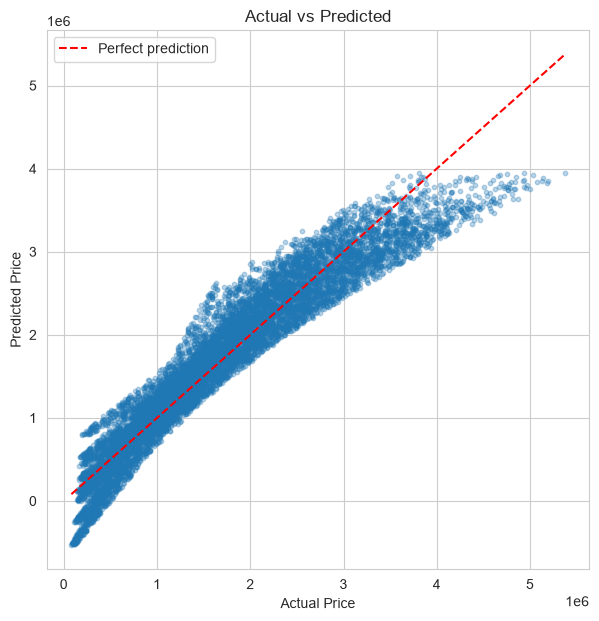

In [30]:
plt.figure(figsize=(7, 7))
plt.scatter(y_test, y_test_pred, alpha=0.3, s=10)

lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted")
plt.legend()
plt.show()

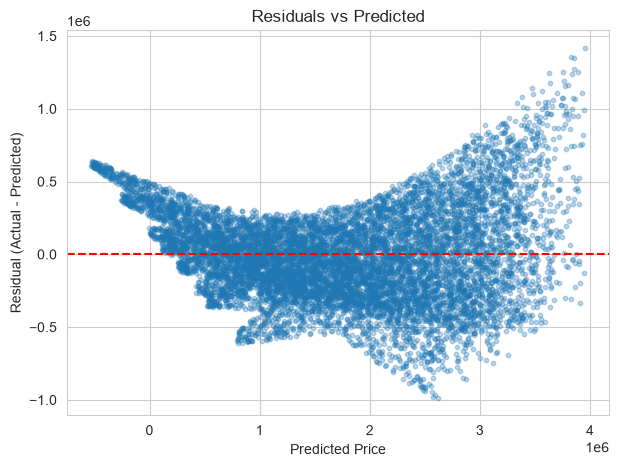

In [31]:
residuals = y_test - y_test_pred

plt.figure(figsize=(7, 5))
plt.scatter(y_test_pred, residuals, alpha=0.3, s=10)
plt.axhline(0, color="r", linestyle="--")

plt.xlabel("Predicted Price")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residuals vs Predicted")
plt.show()

In [32]:
coef_df = (
    pd.DataFrame({"Feature": X_train_df.columns, "Coefficient": model.coef_})
    .sort_values("Coefficient", key=abs, ascending=False)
    .reset_index(drop=True)
)
coef_df

,Feature,Coefficient
0,standardscaler__Area_sqft,912808.339202
1,onehotencoder__Location_Houston,-689114.353653
2,onehotencoder__Location_San Francisco,629918.284147
3,onehotencoder__Location_Chicago,-430239.754263
4,onehotencoder__Location_New York,359516.793970
5,onehotencoder__Location_Boston,257828.504892
6,onehotencoder__Location_Miami,-165128.500041
7,onehotencoder__Location_Los Angeles,94439.807037
8,onehotencoder__Location_Seattle,-57220.782089
9,onehotencoder__Property_Type_Townhouse,5038.357679


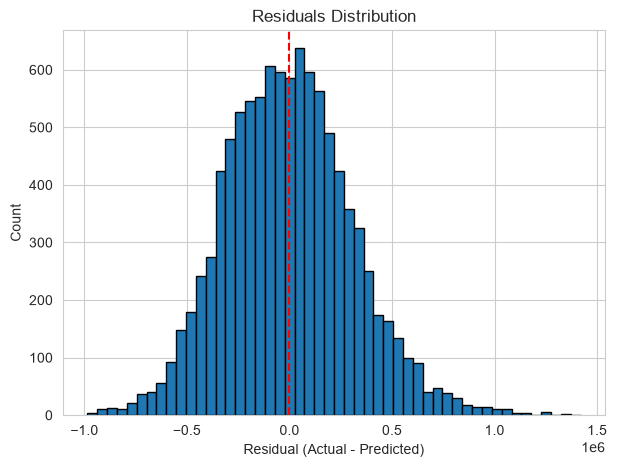

In [33]:
residuals = y_test - y_test_pred

plt.figure(figsize=(7, 5))
plt.hist(residuals, bins=50, edgecolor="black")
plt.axvline(0, color="r", linestyle="--")
plt.xlabel("Residual (Actual - Predicted)")
plt.ylabel("Count")
plt.title("Residuals Distribution")
plt.show()